# Drought Monitoring in Western Kansas with SPEI (12-month)

This notebook analyzes drought conditions in western Kansas using the **Standardised Precipitation–Evapotranspiration
Index (SPEI)** from the global **SPEIbase v2.9** dataset (`CSIC/SPEI/2_9`, 0.5° grid, monthly) in Google Earth Engine.
The 12-month SPEI reflects long-term (hydrological/agricultural) water balance anomalies.

Each month is assigned a drought class from the regional mean SPEI:

| SPEI-12 | Class |
|---|---|
| ≤ −2.0 | Severe Drought |
| −2.0 to −1.0 | Moderate Drought |
| −1.0 to 0 | Mild Drought |
| 0 to 1.0 | Normal |
| > 1.0 | No Drought (wet) |

**Outputs:** monthly SPEI table, class frequencies, trend statistics (Theil–Sen, Mann–Kendall), drought events
(run theory), time-series figures, a year × month heatmap, and a map of the driest month.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

In [11]:
%pip install earthengine-api numpy pandas matplotlib requests pillow scipy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, io
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import requests
from PIL import Image
from scipy import stats

ee.Initialize(project="replace with your Earth Engine project ID") 

FIG_DIR, OUT_DIR = "figures/spei", "outputs/spei"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

## 2. Parameters

In [17]:
# --- Region of interest: Western Kansas ---
WEST_OF_LON = -99.0   # Kansas spans ~-102.05 to -94.59; use -100.0 for west of the 100th meridian

kansas = (ee.FeatureCollection("TIGER/2018/States")
            .filter(ee.Filter.eq("NAME", "Kansas"))
            .geometry())
west_box = ee.Geometry.Rectangle([-103.0, 36.0, WEST_OF_LON, 41.0])
roi = kansas.intersection(west_box, ee.ErrorMargin(100))

ROI_NAME   = "Western Kansas"
START_YEAR = 1980
END_YEAR   = 2024        # the dataset may end earlier; the actual range is printed below
SCALE      = 55000       # ~0.5° native resolution (m)
DROUGHT_THRESHOLD = -1.0 # SPEI value defining a drought month for event analysis

CLASS_BINS   = [-np.inf, -2.0, -1.0, 0.0, 1.0, np.inf]
CLASS_LABELS = ["Severe Drought", "Moderate Drought", "Mild Drought", "Normal", "No Drought"]
CLASS_COLORS = ["#8c2d04", "#e6550d", "#fdae6b", "#9ecae1", "#2171b5"]

## 3. Load SPEI and compute the regional monthly mean

In [16]:
spei = (ee.ImageCollection("CSIC/SPEI/2_9")
          .select("SPEI_12_month")
          .filterDate(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
          .sort("system:time_start"))

def regional_mean(img):
    val = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=roi,
                           scale=SCALE, maxPixels=1e9).get("SPEI_12_month")
    return ee.Feature(None, {"date": img.date().format("YYYY-MM-dd"), "spei": val})

rows = [f["properties"] for f in spei.map(regional_mean).getInfo()["features"]]

df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"])
df = df.dropna(subset=["spei"]).sort_values("date").reset_index(drop=True)
df["year"], df["month"] = df["date"].dt.year, df["date"].dt.month

# Classification (same thresholds as the original ee.Algorithms.If chain)
df["spei_class"] = pd.cut(df["spei"], bins=CLASS_BINS, labels=CLASS_LABELS, right=True)

df.to_csv(f"{OUT_DIR}/spei12_monthly.csv", index=False)
print(f"Months: {len(df)}  |  {df.date.min():%Y-%m} to {df.date.max():%Y-%m}")
df.head()

C:\Users\moham\anaconda3\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for CSIC/SPEI/2_9! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by CSIC/SPEI/2_11

Learn more: https://developers.google.com/earth-engine/datasets/catalog/CSIC_SPEI_2_9

  warnings.warn(warning, category=DeprecationWarning)


Months: 516  |  1980-01 to 2022-12


,date,spei,year,month,spei_class
0,1980-01-01,0.513424,1980,1,Normal
1,1980-02-01,0.694100,1980,2,Normal
2,1980-03-01,0.836467,1980,3,Normal
3,1980-04-01,0.926828,1980,4,Normal
4,1980-05-01,0.930320,1980,5,Normal


## 4. Summary and trend statistics

In [19]:
t = df["year"] + (df["month"] - 0.5) / 12          # decimal years
y = df["spei"].values

ts_slope, ts_int, ts_lo, ts_hi = stats.theilslopes(y, t)
tau, mk_p = stats.kendalltau(t, y)

i_min, i_max = df["spei"].idxmin(), df["spei"].idxmax()
summary = pd.Series({
    "Period": f"{df.date.min():%Y-%m} to {df.date.max():%Y-%m}",
    "Months analysed": len(df),
    "Mean SPEI-12": y.mean(),
    "Std. dev.": y.std(ddof=1),
    "Driest month": f"{df.date[i_min]:%Y-%m} ({df.spei[i_min]:.2f})",
    "Wettest month": f"{df.date[i_max]:%Y-%m} ({df.spei[i_max]:.2f})",
    f"Months with SPEI ≤ {DROUGHT_THRESHOLD} (%)": 100 * (df.spei <= DROUGHT_THRESHOLD).mean(),
    "Theil–Sen slope (per decade)": 10 * ts_slope,
    "Theil–Sen 95% CI (per decade)": f"[{10*ts_lo:.3f}, {10*ts_hi:.3f}]",
    "Mann–Kendall tau": tau,
    "Mann–Kendall p-value": mk_p,
}, name="value")
summary.to_csv(f"{OUT_DIR}/spei12_summary.csv")
summary.to_frame()

,value
Period,1980-01 to 2022-12
Months analysed,516
Mean SPEI-12,0.153639
Std. dev.,0.890291
Driest month,2012-12 (-2.22)
Wettest month,1993-09 (2.11)
Months with SPEI ≤ -1.0 (%),10.658915
Theil–Sen slope (per decade),-0.114246
Theil–Sen 95% CI (per decade),"[-0.180, -0.050]"
Mann–Kendall tau,-0.103876


> **Note:** SPEI-12 is strongly autocorrelated month to month (each value overlaps the previous 11 months),
so the Mann–Kendall p-value is optimistic. Treat it as indicative, or test annual means instead.

In [20]:
freq = (df["spei_class"].value_counts().reindex(CLASS_LABELS)
          .to_frame("months"))
freq["percent"] = (100 * freq["months"] / freq["months"].sum()).round(1)
freq.to_csv(f"{OUT_DIR}/spei12_class_frequency.csv")
freq

,months,percent
spei_class,,
Severe Drought,6,1.2
Moderate Drought,49,9.5
Mild Drought,164,31.8
Normal,208,40.3
No Drought,89,17.2


## 5. Drought events (run theory)

A drought event is a run of consecutive months with SPEI ≤ the threshold.
**Duration** = number of months, **severity** = sum of |SPEI| over the event,
**intensity** = severity / duration, **peak** = lowest SPEI in the event.

In [21]:
in_drought = df["spei"] <= DROUGHT_THRESHOLD
run_id = (in_drought != in_drought.shift()).cumsum()

events = (df[in_drought]
            .groupby(run_id[in_drought])
            .agg(start=("date", "first"), end=("date", "last"),
                 duration_months=("spei", "size"),
                 severity=("spei", lambda s: -s.sum()),
                 peak_spei=("spei", "min"))
            .reset_index(drop=True))
events["intensity"] = events["severity"] / events["duration_months"]
events = events.sort_values("severity", ascending=False).reset_index(drop=True)
events.round(2).to_csv(f"{OUT_DIR}/spei12_drought_events.csv", index=False)

print(f"Drought events: {len(events)}  |  mean duration: {events.duration_months.mean():.1f} months")
events.head(10).round(2)

Drought events: 7  |  mean duration: 7.9 months


,start,end,duration_months,severity,peak_spei,intensity
0,2011-07-01,2013-07-01,25,40.35,-2.22,1.61
1,2022-03-01,2022-12-01,10,15.78,-1.98,1.58
2,1981-02-01,1981-06-01,5,7.62,-1.75,1.52
3,1988-12-01,1989-05-01,6,7.56,-1.53,1.26
4,2002-05-01,2002-09-01,5,6.72,-1.50,1.34
5,2006-06-01,2006-08-01,3,3.73,-1.29,1.24
6,2000-09-01,2000-09-01,1,1.19,-1.19,1.19


## 6. Figures

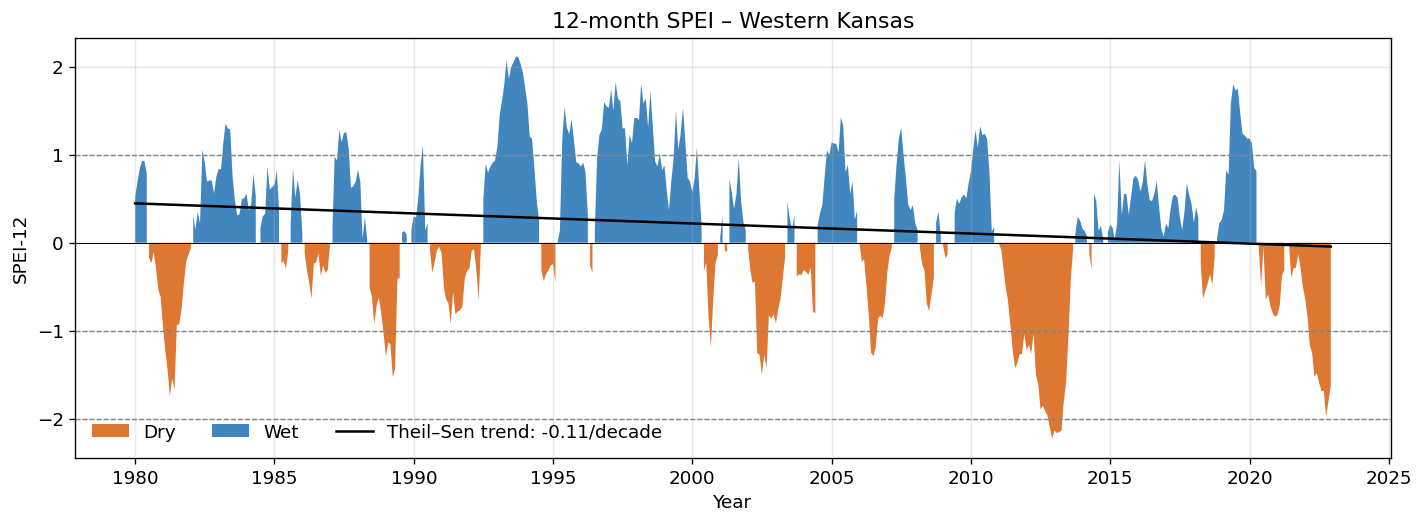

In [22]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(df.date, df.spei, 0, where=df.spei < 0, color="#d95f0e", alpha=0.85, lw=0, label="Dry")
ax.fill_between(df.date, df.spei, 0, where=df.spei >= 0, color="#2171b5", alpha=0.85, lw=0, label="Wet")
for v in (-2, -1, 1):
    ax.axhline(v, color="gray", ls="--", lw=0.8)
ax.plot(df.date, ts_int + ts_slope * t, color="k", lw=1.5,
        label=f"Theil–Sen trend: {10*ts_slope:+.2f}/decade")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="Year", ylabel="SPEI-12", title=f"12-month SPEI – {ROI_NAME}")
ax.legend(frameon=False, loc="lower left", ncol=3); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_spei12_timeseries.png"); plt.show()

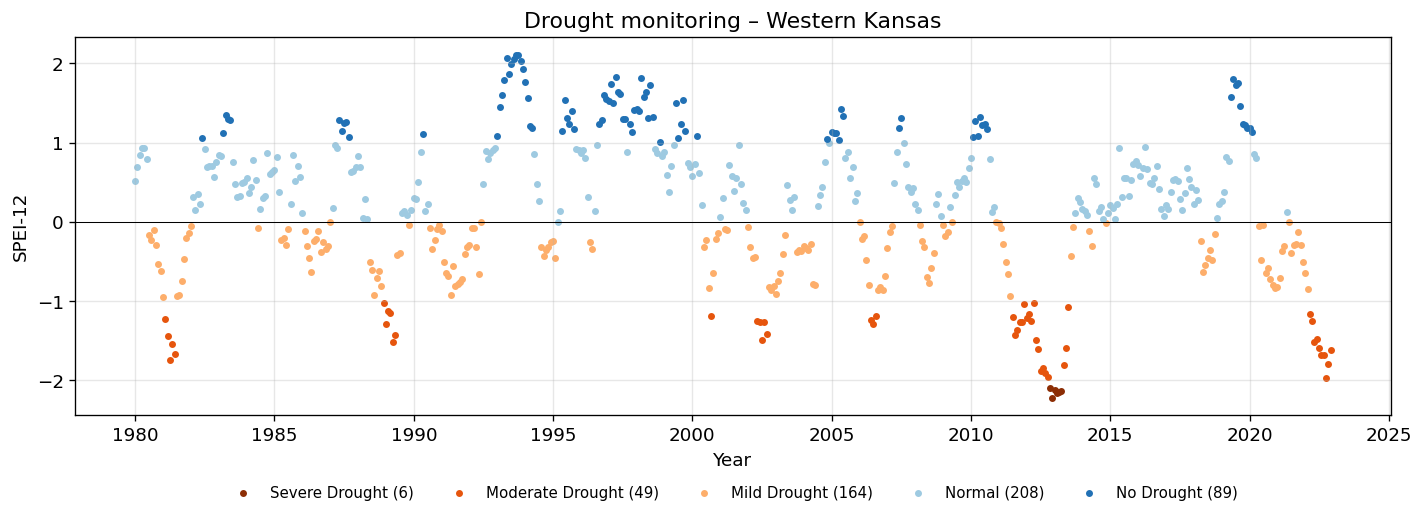

In [23]:
# Equivalent of the original 'Drought Monitoring' scatter chart, coloured by class
fig, ax = plt.subplots(figsize=(12, 4.5))
for label, color in zip(CLASS_LABELS, CLASS_COLORS):
    sub = df[df.spei_class == label]
    ax.scatter(sub.date, sub.spei, s=10, color=color, label=f"{label} ({len(sub)})")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="Year", ylabel="SPEI-12", title=f"Drought monitoring – {ROI_NAME}")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_drought_classes_scatter.png"); plt.show()

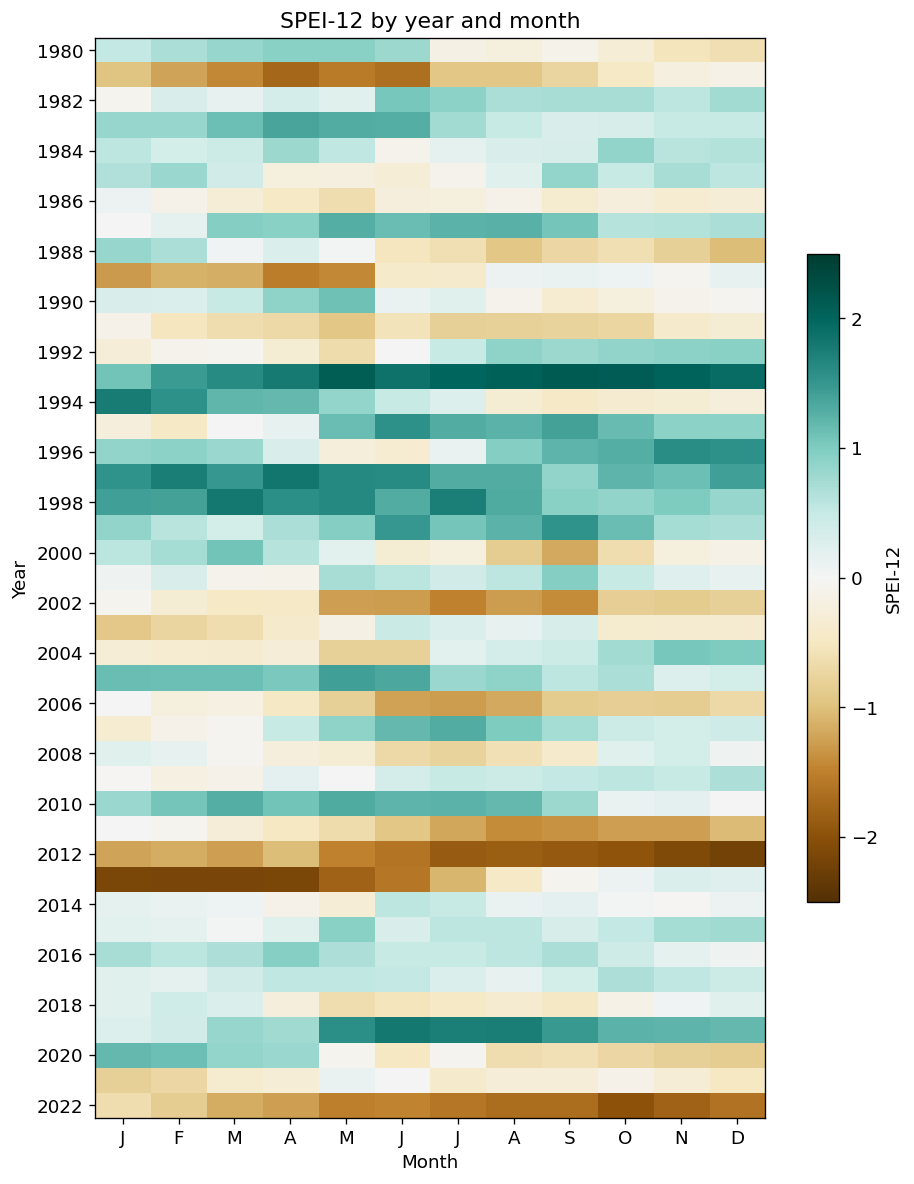

In [24]:
heat = df.pivot(index="year", columns="month", values="spei")
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(heat.values, cmap="BrBG", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_yticks(range(0, len(heat), 2)); ax.set_yticklabels(heat.index[::2])
ax.set(xlabel="Month", ylabel="Year", title="SPEI-12 by year and month")
fig.colorbar(im, ax=ax, label="SPEI-12", shrink=0.6)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_spei12_heatmap.png"); plt.show()

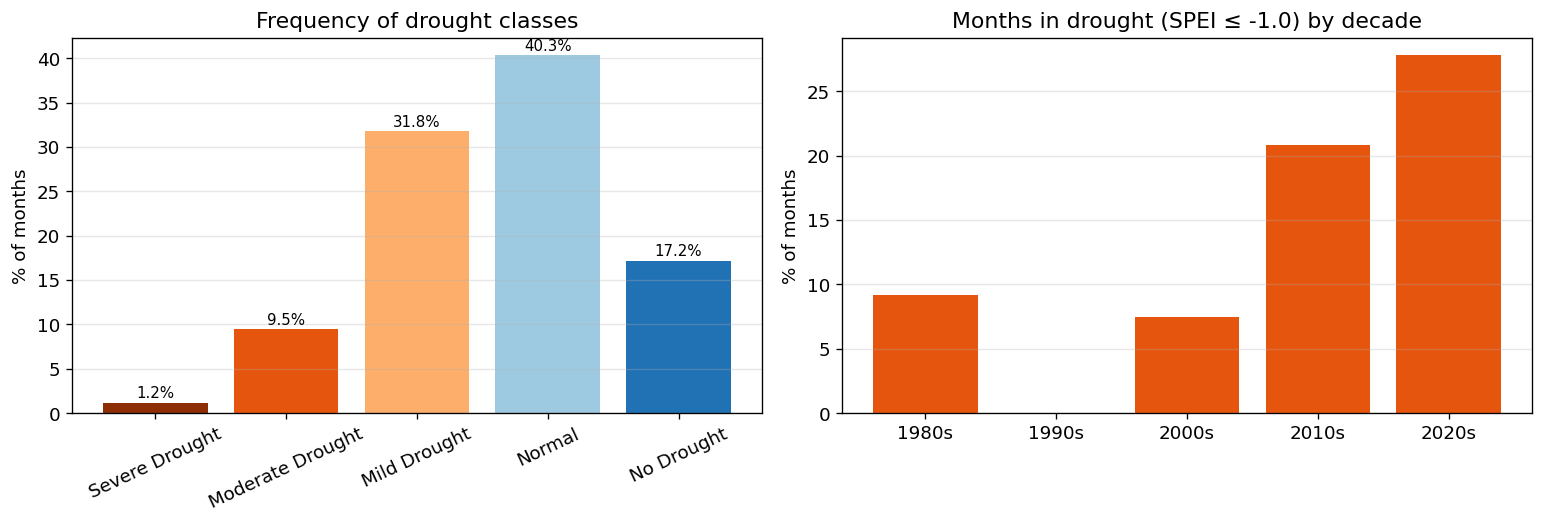

In [25]:
df["decade"] = (df["year"] // 10) * 10
decadal = 100 * (df.spei <= DROUGHT_THRESHOLD).groupby(df.decade).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(freq.index, freq["percent"], color=CLASS_COLORS)
ax1.set(ylabel="% of months", title="Frequency of drought classes")
ax1.tick_params(axis="x", rotation=25)
for i, p in enumerate(freq["percent"]):
    ax1.text(i, p + 0.5, f"{p:.1f}%", ha="center", fontsize=9)

ax2.bar([f"{d}s" for d in decadal.index], decadal.values, color="#e6550d")
ax2.set(ylabel="% of months", title=f"Months in drought (SPEI ≤ {DROUGHT_THRESHOLD}) by decade")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/04_class_frequency_decadal.png"); plt.show()

## 7. Map of the driest month

Static image (via `getThumbURL`) so it renders on GitHub. The western Kansas study area is outlined in black,
the rest of Kansas in gray.

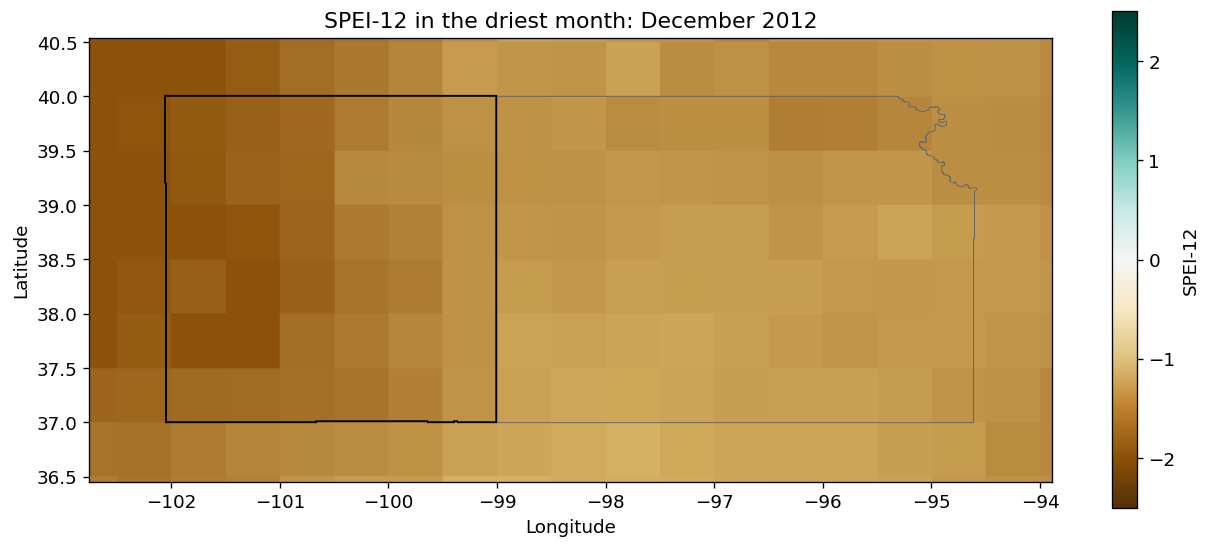

In [26]:
driest = df.loc[df.spei.idxmin(), "date"]
img = (spei.filterDate(driest.strftime("%Y-%m-01"),
                       (driest + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d"))
           .first())

view = kansas.buffer(60000).bounds()
brbg = ["8c510a", "d8b365", "f6e8c3", "f5f5f5", "c7eae5", "5ab4ac", "01665e"]
layer = img.visualize(min=-2.5, max=2.5, palette=brbg)
ks_line  = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(kansas)]), 1, 1).visualize(palette=["666666"])
roi_line = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(roi)]), 1, 2).visualize(palette=["000000"])
composite = layer.blend(ks_line).blend(roi_line)

url = composite.getThumbURL({"region": view, "dimensions": 1000, "crs": "EPSG:4326", "format": "png"})
arr = np.array(Image.open(io.BytesIO(requests.get(url, timeout=120).content)))

b = np.array(view.coordinates().getInfo()[0])
extent = [b[:, 0].min(), b[:, 0].max(), b[:, 1].min(), b[:, 1].max()]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.imshow(arr, extent=extent)
sm = plt.cm.ScalarMappable(cmap="BrBG", norm=plt.Normalize(-2.5, 2.5))
fig.colorbar(sm, ax=ax, label="SPEI-12", shrink=0.8)
ax.set(title=f"SPEI-12 in the driest month: {driest:%B %Y}", xlabel="Longitude", ylabel="Latitude")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/05_spei12_driest_month_map.png"); plt.show()

## 8. Notes

- **Data:** Beguería, S., Vicente-Serrano, S. M., et al. *SPEIbase v2.9*, CSIC. Available in Earth Engine as `CSIC/SPEI/2_9`.
- At 0.5° (~55 km), western Kansas covers only a few dozen grid cells, so the regional mean is a coarse summary.
- Class thresholds follow the original script; adjust `CLASS_BINS` / `CLASS_LABELS` to use another scheme
  (e.g. McKee et al. 1993 SPI categories).